# 02 - Modelo: benchmark, validação espaço-temporal, intervalos, D+1, SHAP e mapas

**Validação principal**: estações inteiras fora do treino (GroupKFold, 5 folds) **e** período posterior (teste a partir de jul/2022). A validação aleatória aparece só como referência otimista.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
fig = lambda n: display(Image(filename=str(ROOT / 'reports/figures' / n)))
met = lambda n: pd.read_csv(ROOT / 'reports/metrics' / n)

In [2]:
b = met('benchmark_estimativa.csv'); b[['modelo','n','MAE','RMSE','R2','ganho_MAE_vs_baseline_%','acerto_faixa_IQAr','MAE_std_folds']].round(3)

,modelo,n,MAE,RMSE,R2,ganho_MAE_vs_baseline_%,acerto_faixa_IQAr,MAE_std_folds
0,LightGBM regularizado (offset IDW),7761,3.005,4.767,0.722,3.445,0.944,0.499
1,Ensemble RF + LightGBM reg. (offset IDW),7761,3.009,4.772,0.721,3.322,0.942,0.524
2,Krigagem ordinária,7761,3.078,4.911,0.705,1.104,0.940,0.382
3,XGBoost reg. forte (offset IDW),7761,3.085,4.861,0.711,0.862,0.941,0.506
4,IDW (baseline),7761,3.112,4.867,0.710,0.000,0.943,0.312
5,Random Forest (offset IDW),7761,3.132,4.904,0.706,-0.641,0.940,0.537
6,XGBoost regularizado (offset IDW),7761,3.201,5.039,0.689,-2.866,0.938,0.575
7,LightGBM (offset IDW),7761,3.244,5.038,0.689,-4.241,0.937,0.498
8,XGBoost (offset IDW),7761,3.287,5.156,0.675,-5.632,0.935,0.605
9,LightGBM (offset) sem satélite,7761,3.478,5.455,0.636,-11.762,0.930,0.546


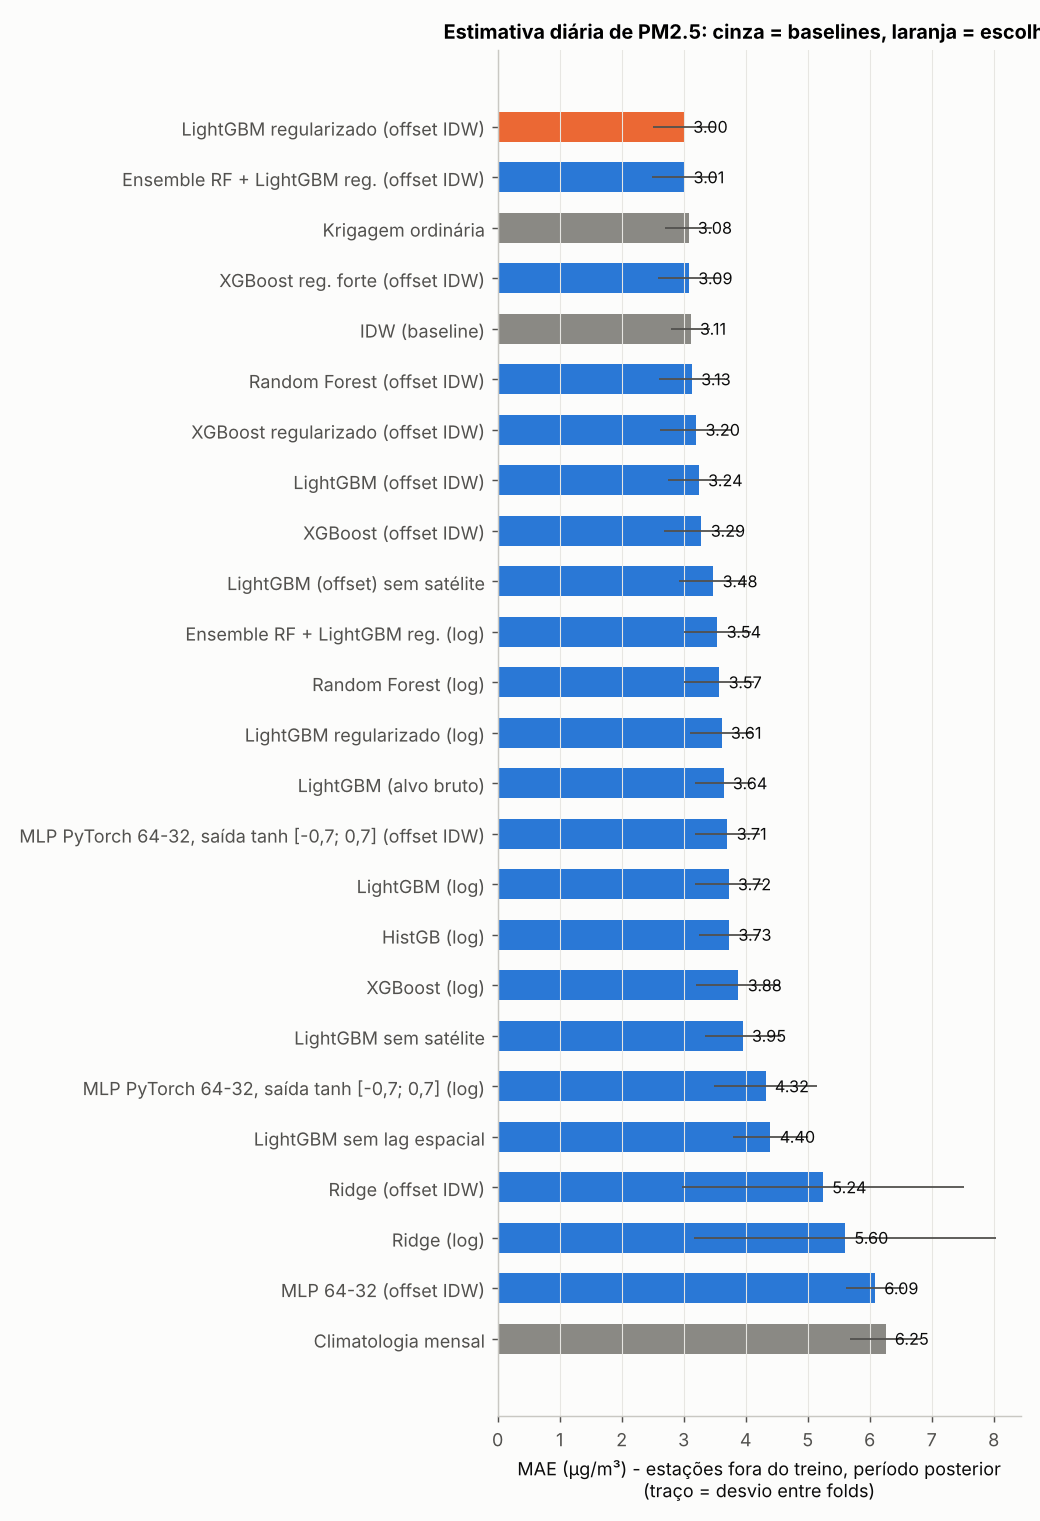

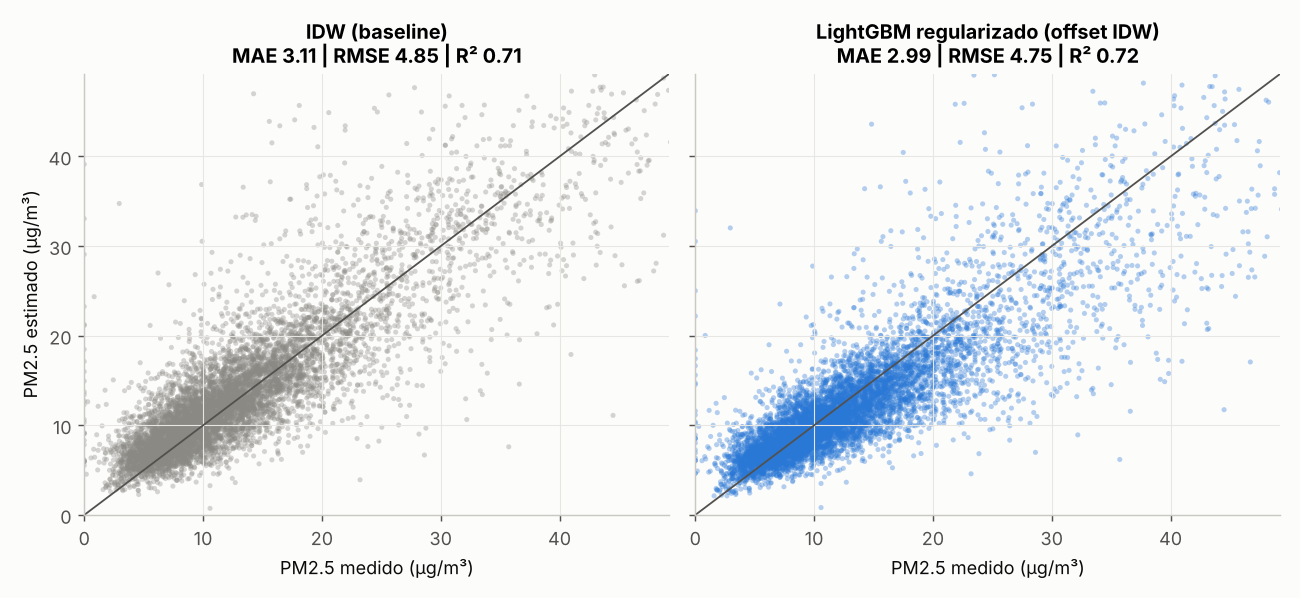

In [3]:
fig('benchmark_mae.png'); fig('dispersao_idw_vs_lgbm.png')

## Intervalo de confiança (90%) - cobertura real no teste

,recorte,metodo,n,cobertura_nominal,cobertura_real,largura_media,cobertura_pm25_>25
0,todos,Quantis LightGBM 5-95% (sem calibrar),7859,0.9,0.795,9.566,0.750
1,todos,CQR (quantis conformalizados),7859,0.9,0.905,13.501,0.847
2,todos,Conformal do resíduo absoluto,7859,0.9,0.920,14.700,0.565
3,T1,Quantis LightGBM 5-95% (sem calibrar),4102,0.9,0.812,12.284,0.768
4,T1,CQR (quantis conformalizados),4102,0.9,0.902,16.386,0.859
5,T1,Conformal do resíduo absoluto,4102,0.9,0.886,15.846,0.575
6,T2,Quantis LightGBM 5-95% (sem calibrar),3757,0.9,0.777,6.599,0.468
7,T2,CQR (quantis conformalizados),3757,0.9,0.909,10.351,0.660
8,T2,Conformal do resíduo absoluto,3757,0.9,0.957,13.448,0.404


,faixa,n,cobertura_cqr,largura_cqr
0,0-15,5471.0,0.918,9.954
1,15-25,1598.0,0.903,17.264
2,25-35,478.0,0.852,27.179
3,35-50,233.0,0.846,35.439
4,>50,52.0,0.808,46.100


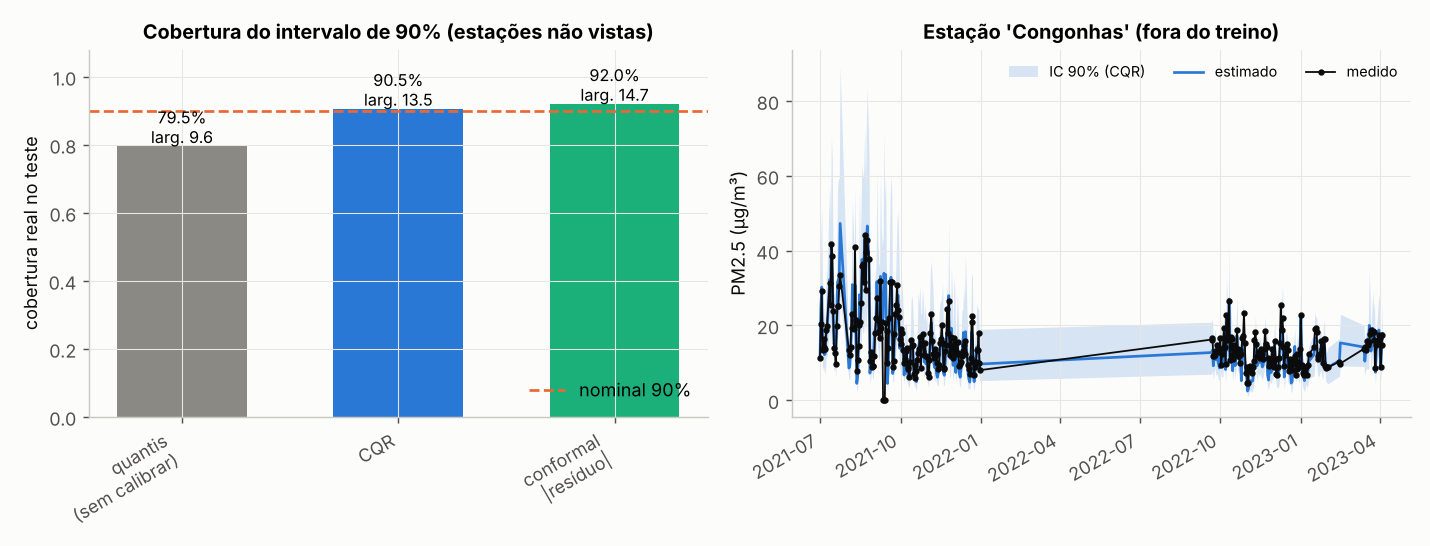

In [4]:
display(met('intervalos.csv').round(3)); display(met('intervalos_por_faixa.csv').round(3)); fig('intervalos.png')

## Previsão do dia seguinte x persistência

,cenario,metodo,n,MAE,RMSE,R2,acerto_faixa_IQAr,ganho_MAE_vs_baseline_%
0,A) local com estação,Persistência (amanhã = hoje),7376,4.303,6.440,0.493,0.922,NaN
1,A) local com estação,LightGBM reg. (offset IDW) D+1,7376,3.400,5.160,0.674,0.940,20.983
2,A) local com estação,Persistência (amanhã = hoje),3901,5.216,7.650,0.503,0.872,NaN
3,A) local com estação,LightGBM reg. (offset IDW) D+1,3901,4.231,6.212,0.672,0.898,18.897
4,A) local com estação,Persistência (amanhã = hoje),3475,3.277,4.728,0.083,0.978,NaN
5,A) local com estação,LightGBM reg. (offset IDW) D+1,3475,2.467,3.632,0.459,0.987,24.711
6,B) local sem estação,Persistência do IDW de hoje,7375,4.918,7.178,0.370,0.910,NaN
7,B) local sem estação,LightGBM reg. (offset IDW) D+1,7375,3.978,6.092,0.546,0.928,19.099
8,B) local sem estação,Persistência do IDW de hoje,3901,5.925,8.618,0.369,0.848,NaN
9,B) local sem estação,LightGBM reg. (offset IDW) D+1,3901,4.983,7.495,0.522,0.876,15.903


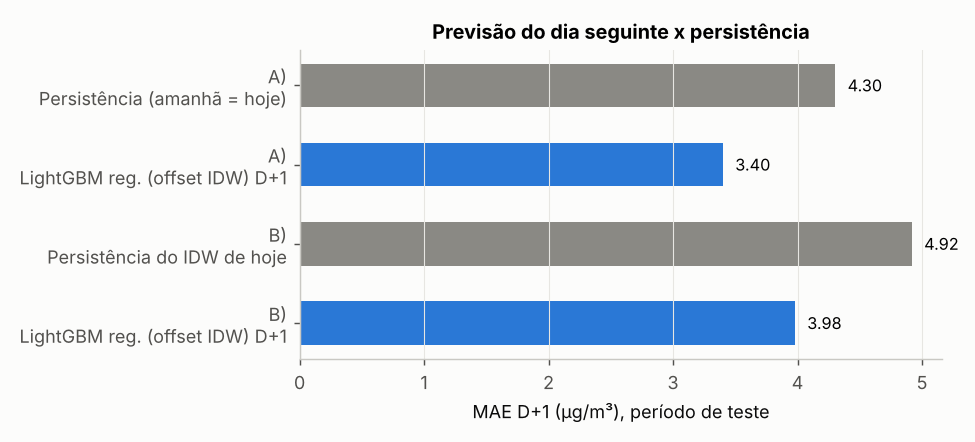

In [5]:
display(met('previsao_d1.csv')[['cenario','metodo','n','MAE','RMSE','R2','acerto_faixa_IQAr','ganho_MAE_vs_baseline_%']].round(3)); fig('previsao_d1.png')

## Explicação (SHAP)

,variavel,shap_medio_abs
0,idw,0.0806
1,built,0.0280
2,tree_5km,0.0247
3,built_5km,0.0216
4,prev_tp,0.0183
5,crop_5km,0.0179
6,elev,0.0173
7,idw_dmin,0.0156
8,grass_5km,0.0150
9,no2_filled,0.0135


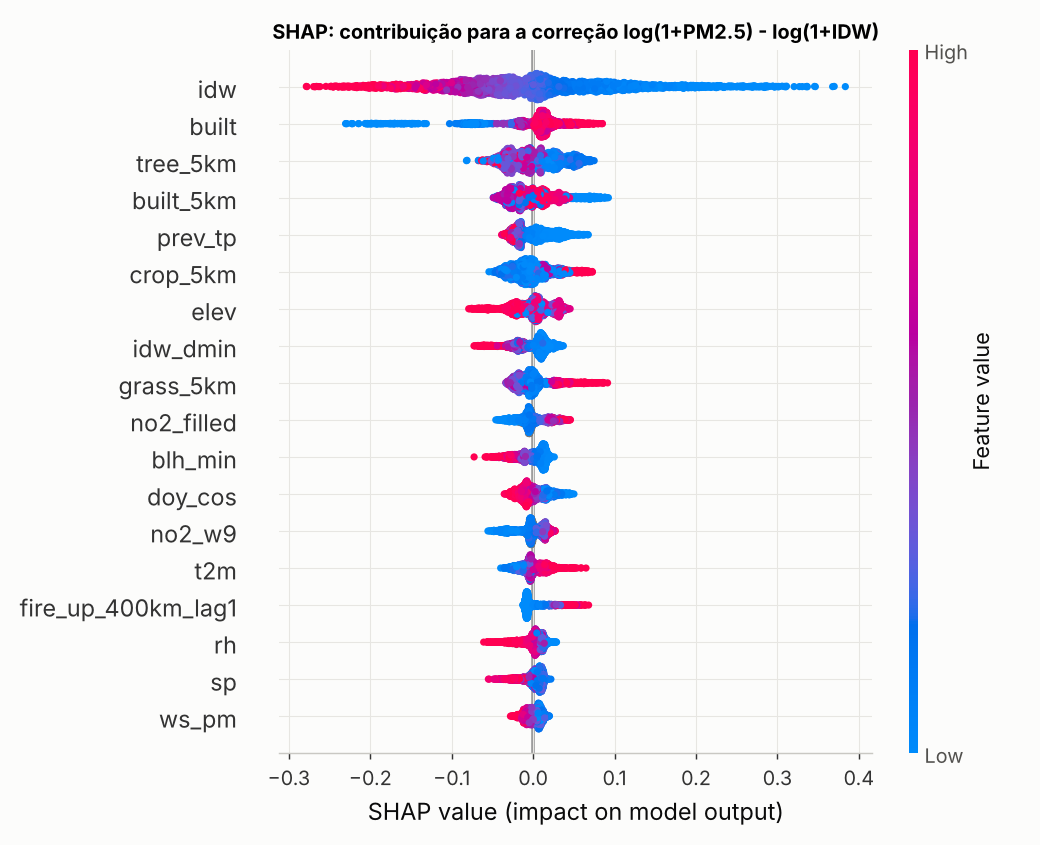

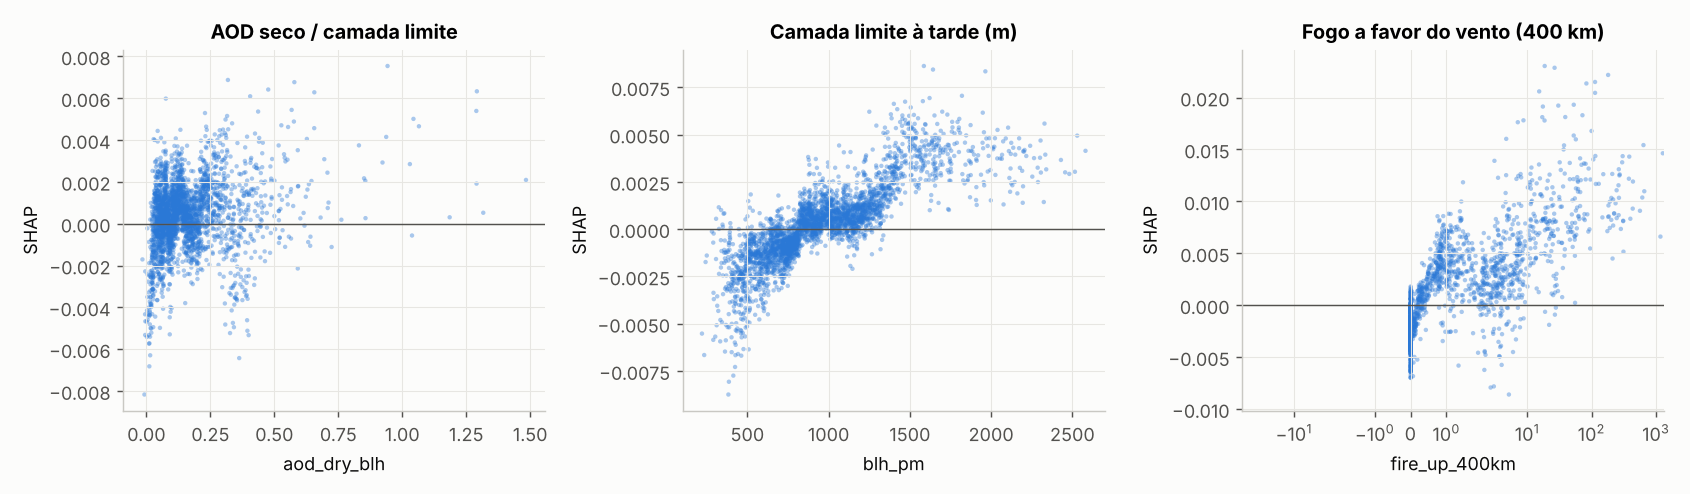

In [6]:
display(met('shap_importancia.csv').head(15).round(4)); fig('shap_resumo.png'); fig('shap_dependencia.png')

In [7]:
display(Markdown('Exemplo local (maior PM2.5 previsto na amostra de teste):')); met('shap_exemplo_local.csv')

Exemplo local (maior PM2.5 previsto na amostra de teste):

,Unnamed: 0,shap,valor
0,idw,-0.2022,58.4826
1,tree_5km,0.0550,0.0939
2,built,0.0495,0.7733
3,crop_5km,0.0432,0.0043
4,built_5km,0.0429,0.8368
5,elev,0.0396,722.8947
6,fire_up_400km_lag1,0.0378,170.9090
7,no2_filled,0.0343,143.1364
8,prev_tp,0.0315,0.0000
9,no2,0.0226,184.3058


## Episódios extremos (fumaça)

,regime,modelo,n,PM2.5_medio,MAE,vies,AOD_medio,frac_sem_AOD_obs
0,PM2.5 alto sem fogo (≥ p95),IDW (baseline),179,38.93,7.33,-5.81,0.31,0.12
1,PM2.5 alto sem fogo (≥ p95),LightGBM regularizado (offset IDW),179,38.93,9.28,-7.79,0.31,0.12
2,fumaça (fogo a favor do vento ≥ p95),IDW (baseline),393,34.32,8.03,1.31,0.28,0.10
3,fumaça (fogo a favor do vento ≥ p95),LightGBM regularizado (offset IDW),393,34.32,8.85,-3.68,0.28,0.10
4,normal,IDW (baseline),7286,11.85,2.74,0.84,0.40,0.53
5,normal,LightGBM regularizado (offset IDW),7286,11.85,2.52,-0.48,0.40,0.53


,date,pm25,pred,idw,err,fogo,aod,sem_aod
0,2021-09-14,32.90,26.28,34.36,-6.62,66.77,0.39,1.00
1,2021-09-09,22.41,17.00,22.00,-5.41,142.42,0.71,0.00
2,2021-09-19,28.80,24.12,30.15,-4.67,8.44,0.48,0.00
3,2021-09-25,22.67,18.08,23.61,-4.59,0.49,0.78,0.77
4,2021-09-21,32.36,27.81,34.72,-4.56,9.05,0.53,0.09
5,2021-09-10,20.16,15.68,20.17,-4.48,2.59,0.65,1.00
6,2021-08-26,37.94,33.57,38.21,-4.37,168.79,0.27,0.00
7,2021-09-08,34.59,30.26,36.28,-4.34,570.37,0.40,0.09
8,2021-09-26,24.03,19.80,24.44,-4.23,8.19,0.54,0.10
9,2021-09-15,17.95,13.81,18.09,-4.15,0.01,0.56,1.00


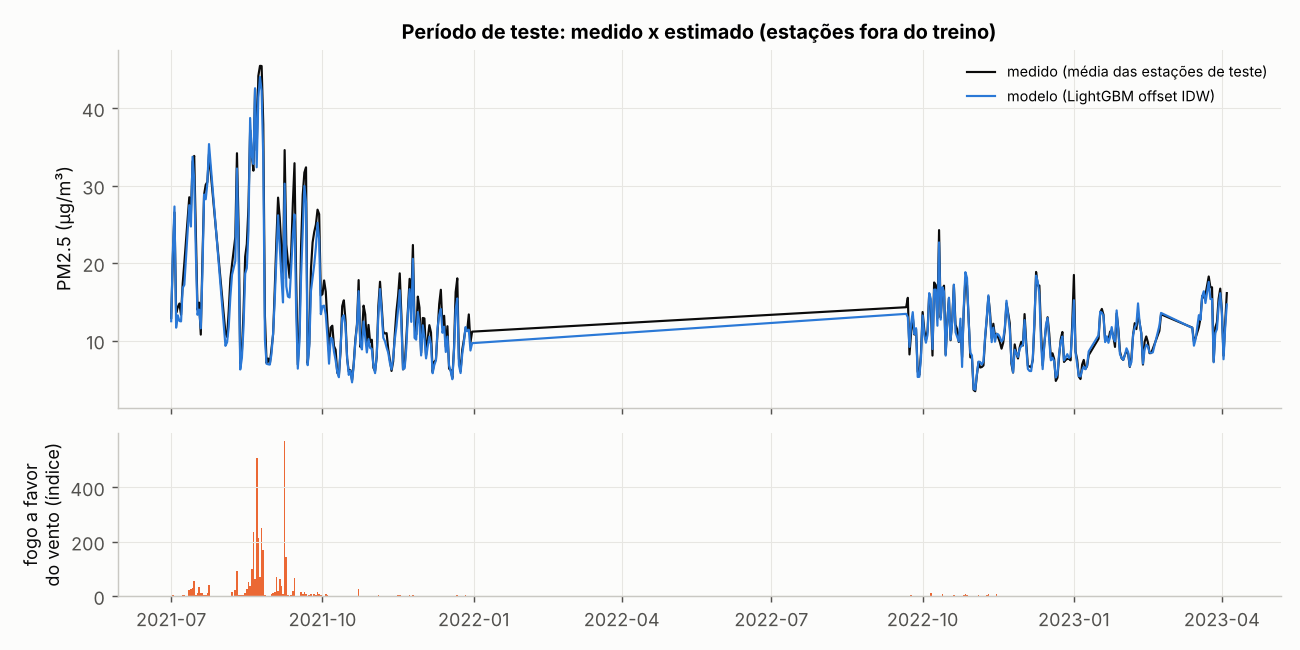

In [8]:
display(met('episodios_extremos.csv').round(2)); display(met('piores_dias.csv').head(10)); fig('episodios_serie.png')

## Mapas diários (PM2.5 e incerteza)

`mapa_pm25_2021-08-24_h0.png`

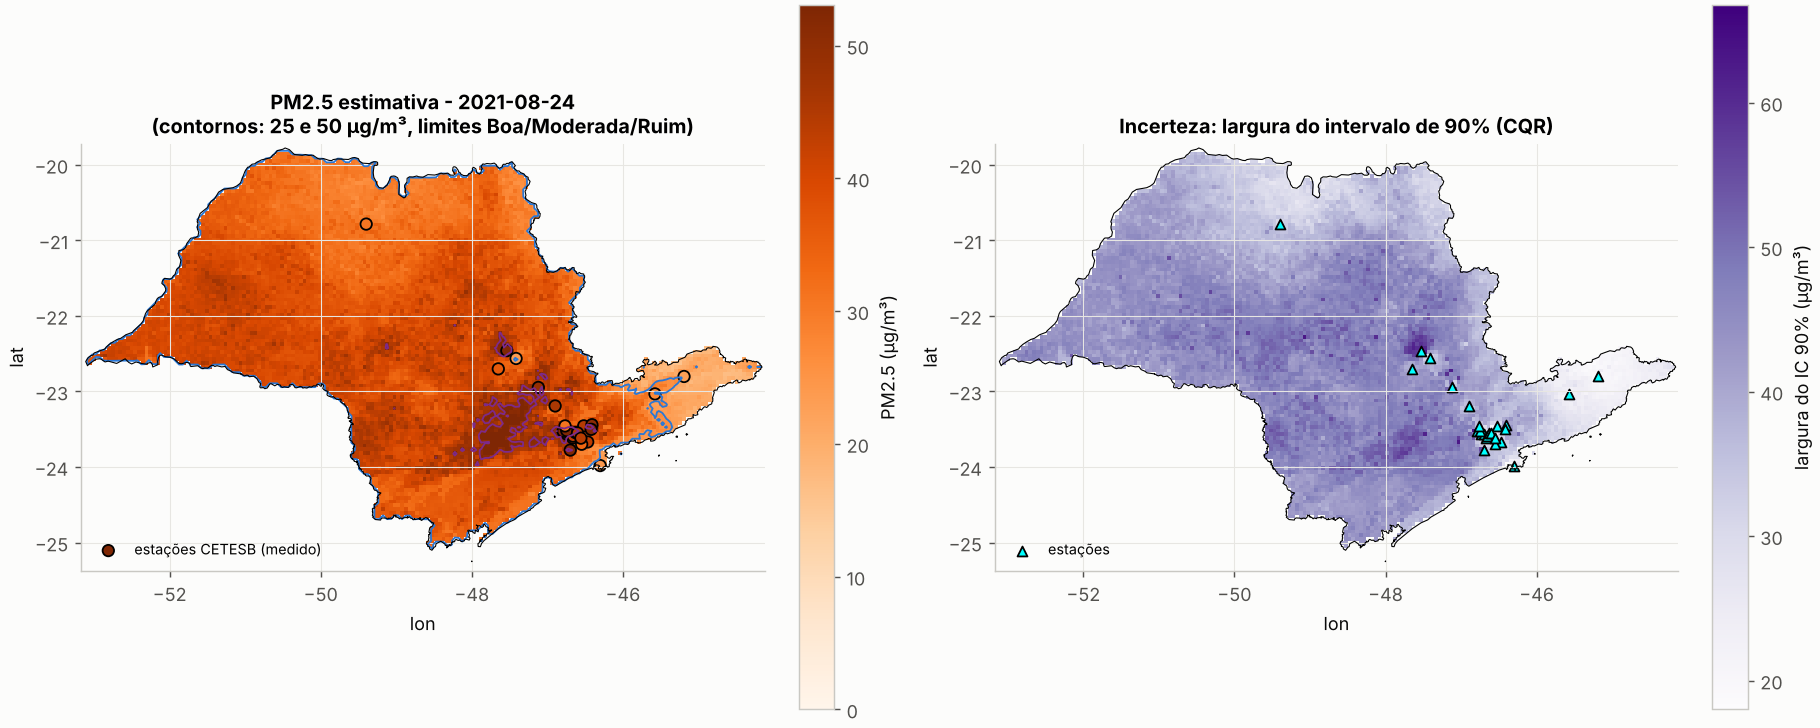

`mapa_pm25_2021-08-24_h1.png`

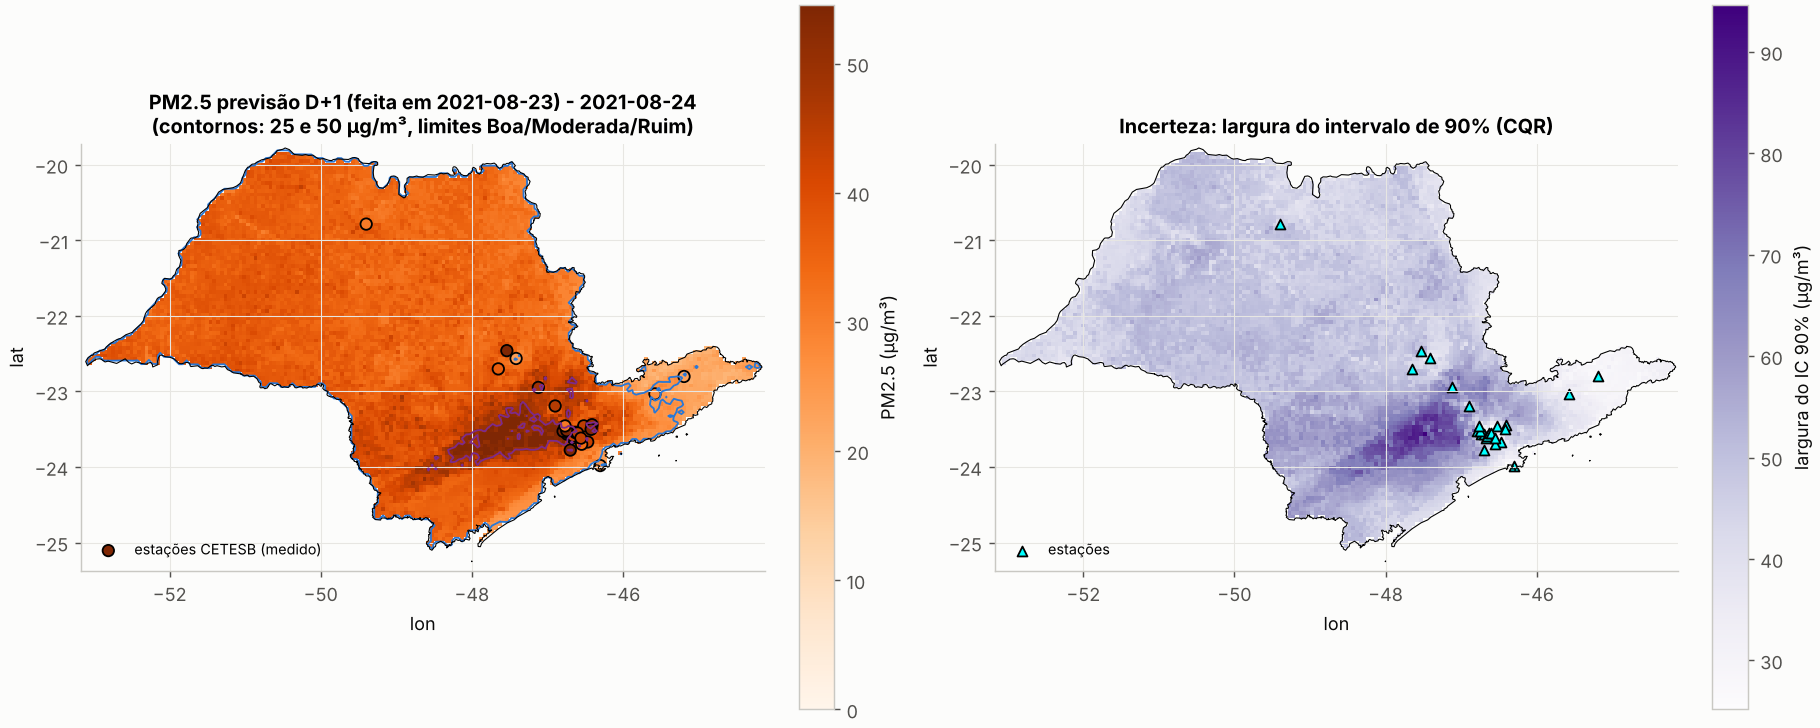

`mapa_pm25_2022-10-11_h0.png`

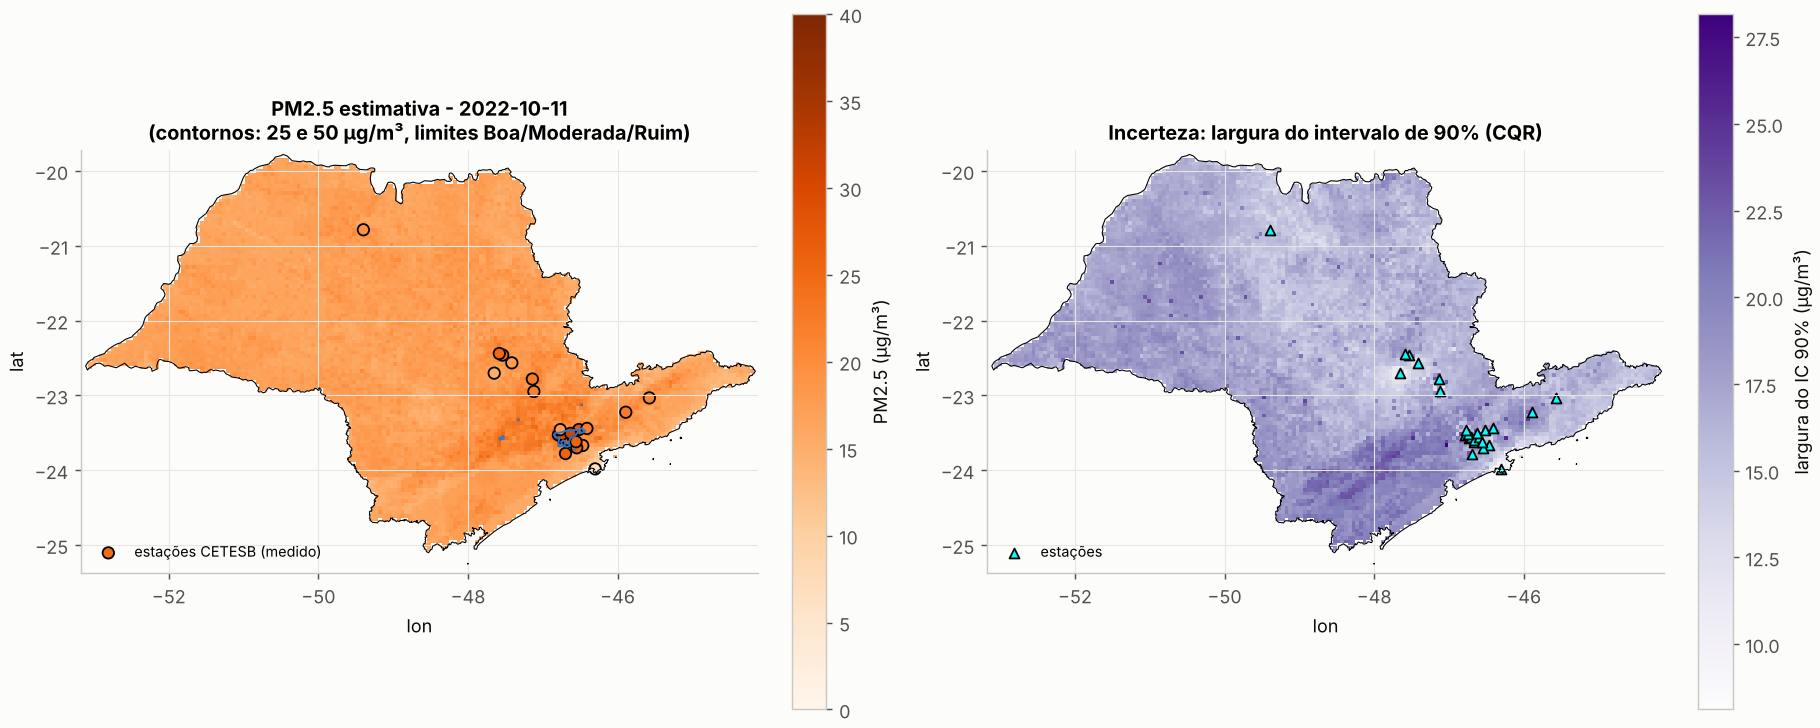

`mapa_pm25_2022-11-16_h0.png`

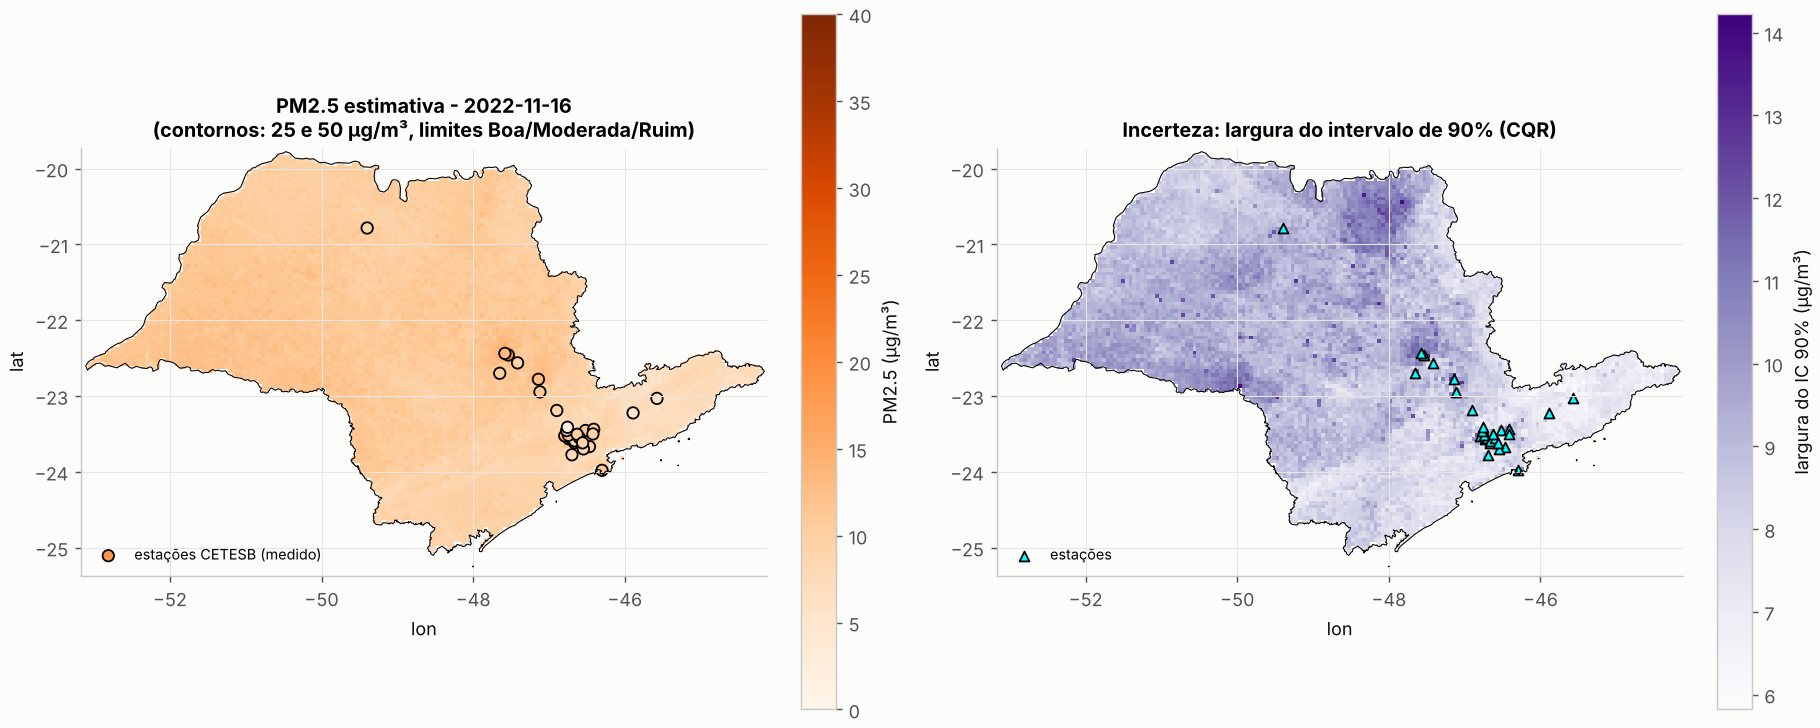

In [9]:
for p in sorted((ROOT/'reports/figures').glob('mapa_pm25_*.png')): display(Markdown(f'`{p.name}`')); fig(p.name)

## Interface: função/CLI/API para coordenada e data

In [10]:
from src.aq.predict import predict_one
print(json.dumps(predict_one(-22.9053, -47.0659, '2022-09-10', 0), ensure_ascii=False, indent=1))
print(json.dumps(predict_one(-22.9053, -47.0659, '2022-09-10', 1), ensure_ascii=False, indent=1))

/home/user/teste_ia/src/aq/features.py:75: RuntimeWarning: Mean of empty slice
  tmean = np.nanmean(np.stack([prev, nxt]), axis=0)


{
 "lat": -22.9053,
 "lon": -47.0659,
 "data_referencia": "2022-09-10",
 "data_alvo": "2022-09-10",
 "horizonte_dias": 0,
 "pm25_ug_m3": 14.2,
 "intervalo_90": [
  8.8,
  18.1
 ],
 "faixa_iqar": "Boa",
 "padrao_24h_vigente": {
  "norma": "Resolução CONAMA 491/2018 (e 506/2024)",
  "etapa": "PI-1",
  "valor": 60.0
 },
 "ultrapassa_padrao": false,
 "diagnostico": {
  "aod_disponivel": true,
  "aod_nivel_preenchimento": 0,
  "estacoes_usadas_idw": 0,
  "dist_estacao_mais_proxima_km": 7.1
 },
 "fonte": "modelo LightGBM + CQR (Parte 1); satélite GOES-16, ERA5, rede CETESB via OpenAQ"
}
{
 "lat": -22.9053,
 "lon": -47.0659,
 "data_referencia": "2022-09-10",
 "data_alvo": "2022-09-11",
 "horizonte_dias": 1,
 "pm25_ug_m3": 11.1,
 "intervalo_90": [
  6.7,
  16.4
 ],
 "faixa_iqar": "Boa",
 "padrao_24h_vigente": {
  "norma": "Resolução CONAMA 491/2018 (e 506/2024)",
  "etapa": "PI-1",
  "valor": 60.0
 },
 "ultrapassa_padrao": false,
 "diagnostico": {
  "aod_disponivel": true,
  "aod_nivel_preench